# code_096 · Point anomalies novelty and density scores

**Book:** section 19.4. A self-contained clustering-and-anomaly laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_19_GUIDE.md), [run evidence](../CHAPTER_19_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_096).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1996;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1996


<a id="scores"></a>
## A score defines unusualness relative to a reference

Generate an admitted reference of480central bivariate-normal cases (correlation.95) plus20rare valid cases near[5,5]. Independent calibration has240central+10rarevalid, the same4%mixture fraction. Final diagnostics retain200central,20rarevalid,20isolated-load cases near[4.5,0] and20unusual combinations near[1.8,-1.8]. The last two are declared off-reference implants, not automatically errors or damage; rare-valid provenance is separately known only in this synthetic fixture. Cohort counts are constructed and do not estimate operational prevalence.

Fit training-only StandardScaler. Compare maximum marginal median/MAD score, robust MinCovDet squared Mahalanobis score, IsolationForest100, LOF20 with novelty=True, OneClassSVM(nu.05,gamma='scale') and full two-component GaussianMixture negative log density. All scores are oriented HIGH=more unusual. Fit only admitted reference records; score LOF calibration/final records only, never its fitting cases through novelty score_samples. Each threshold is the independent calibration95th score percentile, fixed before final labels. None of these scores is automatically an anomaly probability, and threshold calibration does not establish nominal alarm control on another population.


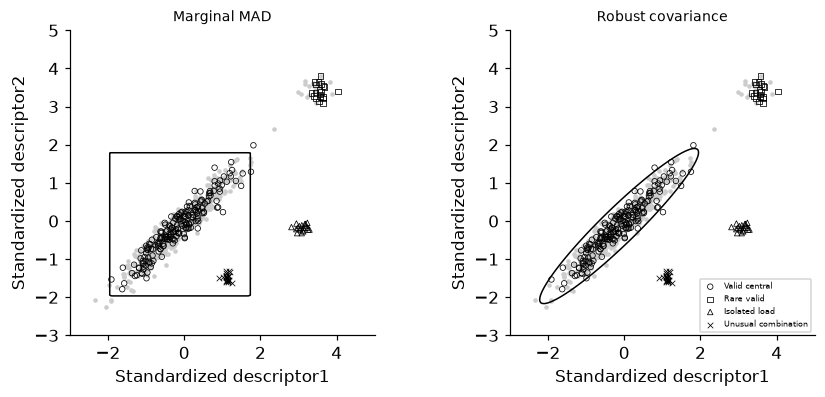

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.covariance import MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.mixture import GaussianMixture
cov=np.array([[1.,.95],[.95,1.]])
def central(n):return rng.multivariate_normal([0.,0.],cov,size=n)
def rare(n):return rng.normal([5.,5.],.25,(n,2))
X=np.vstack([central(480),rare(20)]);Xc=np.vstack([central(240),rare(10)]);cohorts={'Valid central':central(200),'Rare valid':rare(20),'Isolated load':rng.normal([4.5,0.],.15,(20,2)),'Unusual combination':rng.normal([1.8,-1.8],.12,(20,2))};sc=StandardScaler().fit(X);S=sc.transform(X);C=sc.transform(Xc);center=np.median(S,axis=0);mad=1.4826*np.median(np.abs(S-center),axis=0);assert np.all(mad>0);robust=MinCovDet(support_fraction=.85,random_state=SEED).fit(S);isolation=IsolationForest(n_estimators=100,contamination='auto',random_state=SEED,n_jobs=1).fit(S);lof=LocalOutlierFactor(n_neighbors=20,novelty=True,n_jobs=1).fit(S);oneclass=OneClassSVM(nu=.05,gamma='scale').fit(S);density=GaussianMixture(2,covariance_type='full',n_init=5,reg_covar=1e-4,random_state=SEED).fit(S);assert density.converged_
scorers={'Marginal MAD':lambda a:np.max(np.abs((a-center)/mad),axis=1),'Robust covariance':lambda a:robust.mahalanobis(a),'Isolation forest':lambda a:-isolation.score_samples(a),'LOF novelty':lambda a:-lof.score_samples(a),'One-class SVM':lambda a:-oneclass.score_samples(a),'Mixture density':lambda a:-density.score_samples(a)};thresholds={};rows=[];matrix=[]
for name,score in scorers.items():
 calibration=score(C);threshold=float(np.quantile(calibration,.95));thresholds[name]=threshold;record={'method':name,'calibration_threshold':threshold,'calibration_rows':250,'calibration_alarm_fraction_strict_greater':float(np.mean(calibration>threshold)),'final_cohorts':[]};line=[]
 for label,a in cohorts.items():
  value=score(sc.transform(a));assert value.shape==(len(a),) and np.isfinite(value).all();alarms=value>threshold;record['final_cohorts'].append({'cohort':label,'rows':len(a),'alarms':int(alarms.sum()),'alarm_fraction':float(alarms.mean())});line.append(float(alarms.mean()))
 rows.append(record);matrix.append(line)
RESULTS['scores']=rows;RESULTS['reference_contract']={'fit_central':480,'fit_rare_valid':20,'calibration_central':240,'calibration_rare_valid':10,'rare_valid_reference_fraction':.04,'LOF_fitting_rows_scored_as_novelty':False,'final_cohort_counts':{k:len(v) for k,v in cohorts.items()},'threshold_quantile':.95,'scores_are_anomaly_probabilities':False,'density_units':'training-standardized descriptor coordinates'}
fig,axes=plt.subplots(1,2,figsize=(8,3.5));xx,yy=np.meshgrid(np.linspace(-3,5,160),np.linspace(-3,5,160));grid=np.column_stack([xx.ravel(),yy.ravel()]);markers=['o','s','^','x']
for ax,name in zip(axes,['Marginal MAD','Robust covariance']):
 ax.scatter(*S.T,s=4,color='.8')
 for (label,a),marker in zip(cohorts.items(),markers):
  z=sc.transform(a);ax.scatter(*z.T,s=13,marker=marker,facecolors='none' if marker!='x' else 'black',edgecolors='black' if marker!='x' else None,linewidths=.5,label=label)
 zz=scorers[name](grid).reshape(xx.shape);ax.contour(xx,yy,zz,levels=[thresholds[name]],colors='black',linewidths=1);ax.set(xlabel='Standardized descriptor1',ylabel='Standardized descriptor2',title=name,aspect='equal',xlim=(-3,5),ylim=(-3,5))
axes[1].legend(fontsize=5,loc='lower right');plt.show()


<a id="alarms"></a>
## Rarity, invalidity and review labels are different claims

The same numeric score can reject a legitimate minority regime or miss an unusual joint combination, depending on what reference structure it encodes. Robust covariance targets a dominant elliptical center; the mixture density can represent a separate valid mode if its assumptions and fitting succeed. Local density contrasts need their own neighborhood support, while isolation and one-class boundaries use other definitions. Final per-cohort alarm counts retain known provenance, rather than converting every low-density record into an error label. The five-percent calibration quantile is an empirical operating choice on250records, not a promise of the same rate after prevalence, measurement or context changes. Density values also depend on coordinates and are not point probabilities.


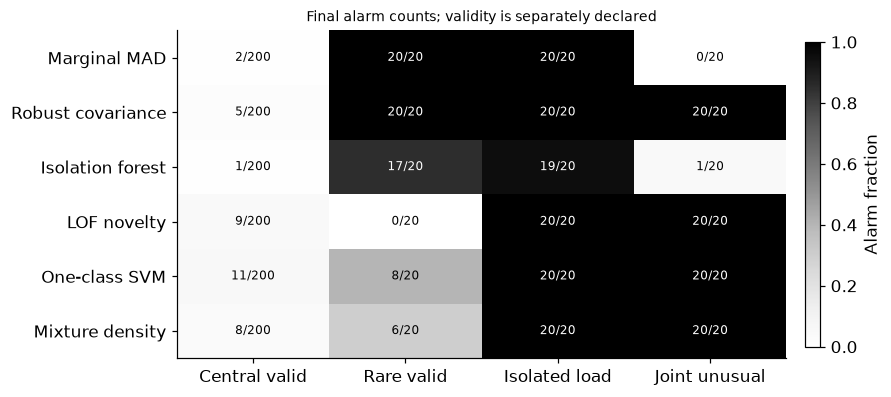

In [3]:
assert lof.novelty is True;assert set(cohorts)=={'Valid central','Rare valid','Isolated load','Unusual combination'};assert np.asarray(matrix).shape==(6,4)
fig,ax=plt.subplots(figsize=(8,3.5));im=ax.imshow(matrix,cmap='Greys',vmin=0,vmax=1,aspect='auto')
for i,row in enumerate(rows):
 for j,c in enumerate(row['final_cohorts']):ax.text(j,i,f"{c['alarms']}/{c['rows']}",ha='center',va='center',fontsize=8,color='white' if matrix[i][j]>.5 else 'black')
ax.set(xticks=range(4),xticklabels=['Central valid','Rare valid','Isolated load','Joint unusual'],yticks=range(6),yticklabels=list(scorers),title='Final alarm counts; validity is separately declared');fig.colorbar(im,ax=ax,fraction=.025,pad=.03,label='Alarm fraction');plt.show()


In [4]:
summary={'example_id':'code_096','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['marginal versus joint unusualness', 'robust covariance isolation local density and one-class boundaries', 'LOF novelty-only scoring contract', 'calibration thresholds versus rare valid observations'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["marginal versus joint unusualness", "robust covariance isolation local density and one-class boundaries", "LOF novelty-only scoring contract", "calibration thresholds versus rare valid observations"], "elapsed_seconds": 0.519, "example_id": "code_096", "hardware": "Darwin arm64 CPU", "results": {"reference_contract": {"LOF_fitting_rows_scored_as_novelty": false, "calibration_central": 240, "calibration_rare_valid": 10, "density_units": "training-standardized descriptor coordinates", "final_cohort_counts": {"Isolated load": 20, "Rare valid": 20, "Unusual combination": 20, "Valid central": 200}, "fit_central": 480, "fit_rare_valid": 20, "rare_valid_reference_fraction": 0.04, "scores_are_anomaly_probabilities": false, "threshold_quantile": 0.95}, "scores": [{"calibration_alarm_fraction_strict_greater": 0.052, "calibration_rows": 250, "calibration_threshold": 2.4963515724933214, "final_cohorts": [{"alarm_fraction": 0.01, "alarms": 2, "coho